# Card detector training results

Run all cells with a Python kernel that has Matplotlib and pandas.
If the kernel needs either package, run `%pip install matplotlib pandas` in a notebook cell.

The figures use the tables in this folder. See the [data dictionary](README.md)
and [benchmark notes](../results.md) for the evaluation settings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

data_dir = Path.cwd()
if not (data_dir / "accuracyByModel.csv").is_file():
    data_dir = data_dir / "docs" / "reportData"

accuracy = pd.read_csv(data_dir / "accuracyByModel.csv").sort_values("model")
training = pd.read_csv(data_dir / "trainingCurves.csv").sort_values(["model", "epoch"])
errors = pd.read_csv(data_dir / "errorsModel3vs5.csv")

model_labels = {
    1: "Model 1",
    2: "Model 2",
    3: "Model 3",
    4: "Model 4",
    5: "Model 5",
}
model_colors = {
    1: "#96A7BD",
    2: "#C5A3FA",
    3: "#61B6FA",
    4: "#FFAC6B",
    5: "#57D6AB",
}

figure_background = "#10151C"
plot_background = "#151D28"
text_color = "#F3F7FC"
muted_text_color = "#B9C8DA"

plt.rcParams.update({
    "font.family": "DejaVu Sans Mono",
    "font.size": 10,
    "figure.facecolor": figure_background,
    "figure.dpi": 130,
    "savefig.facecolor": figure_background,
    "savefig.transparent": False,
    "text.color": text_color,
    "axes.facecolor": plot_background,
    "axes.labelcolor": muted_text_color,
    "axes.titlecolor": text_color,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.titlepad": 10,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": "#45556A",
    "grid.color": "#2A3747",
    "xtick.color": muted_text_color,
    "ytick.color": muted_text_color,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
    "pdf.fonttype": 42,
})


def add_figure_heading(figure, title, subtitle):
    """Add a left-aligned title and evaluation context above the panels."""
    figure.text(0.055, 0.955, title, fontsize=19, fontweight="bold", va="top")
    figure.text(0.055, 0.895, subtitle, fontsize=10, color=muted_text_color, va="top")

## Held-out accuracy across all five models

All models were evaluated on the same 320 real photos with 3,449 labeled corners.
Mean average precision (mAP) summarizes the precision-recall curve across classes.
mAP at 50% box overlap uses a single overlap threshold.
mAP at 50-95% averages across increasingly strict overlap thresholds.

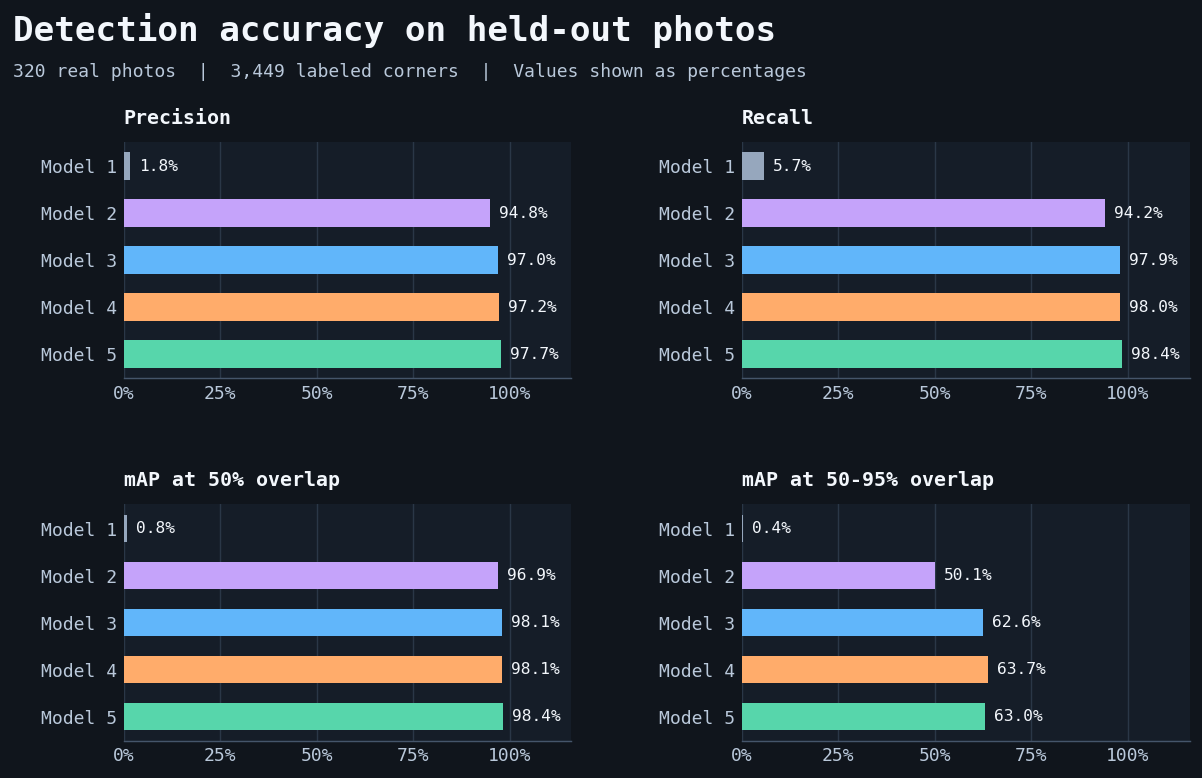

In [2]:
accuracy_figure, accuracy_axes = plt.subplots(2, 2, figsize=(10, 6.4))
accuracy_figure.subplots_adjust(
    left=0.14, right=0.96, top=0.80, bottom=0.08, wspace=0.38, hspace=0.53,
)
add_figure_heading(
    accuracy_figure,
    "Detection accuracy on held-out photos",
    "320 real photos  |  3,449 labeled corners  |  Values shown as percentages",
)

accuracy_metrics = [
    ("real_precision", "Precision"),
    ("real_recall", "Recall"),
    ("real_map50", "mAP at 50% overlap"),
    ("real_map50_95", "mAP at 50-95% overlap"),
]
accuracy_labels = accuracy["model"].map(model_labels)
accuracy_colors = accuracy["model"].map(model_colors)

for axis, (column, label) in zip(accuracy_axes.flat, accuracy_metrics, strict=True):
    scores = accuracy[column]
    bars = axis.barh(accuracy_labels, scores, color=accuracy_colors, height=0.58)
    score_labels = [f"{score:.1%}" for score in scores]
    axis.bar_label(bars, labels=score_labels, padding=5, fontsize=9)
    axis.set_title(label, loc="left")
    axis.set_xlim(0, 1.16)
    axis.set_xticks([0, 0.25, 0.50, 0.75, 1.0])
    axis.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    axis.grid(axis="x")
    axis.invert_yaxis()

plt.show()

## Training and validation image counts

Models 3 and 4 use the same image splits. Model 5 adds rotated copies of real
training photos and keeps the 633-image validation split.

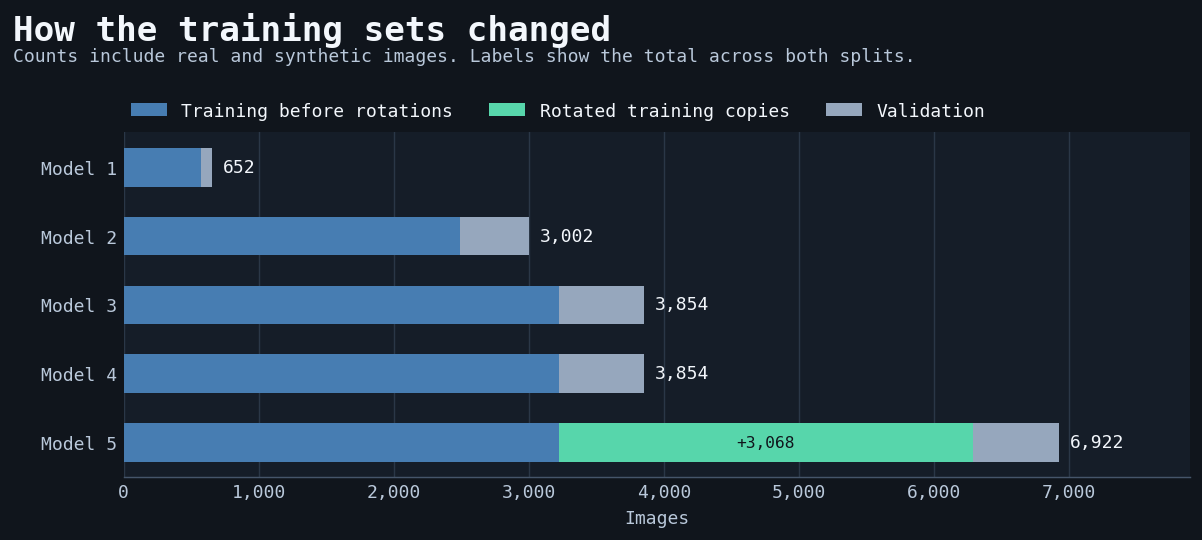

In [3]:
dataset_figure, dataset_axis = plt.subplots(figsize=(10, 4.5))
dataset_figure.subplots_adjust(left=0.14, right=0.96, top=0.75, bottom=0.16)
add_figure_heading(
    dataset_figure,
    "How the training sets changed",
    "Counts include real and synthetic images. Labels show the total across both splits.",
)

training_images = accuracy["train_images"]
rotated_images = accuracy["rotated_copies"]
base_training_images = training_images - rotated_images
validation_images = accuracy["val_images"]
total_images = training_images + validation_images

dataset_axis.barh(
    accuracy_labels, base_training_images, height=0.56,
    color="#477DB2", label="Training before rotations",
)
rotated_bars = dataset_axis.barh(
    accuracy_labels, rotated_images, left=base_training_images, height=0.56,
    color=model_colors[5], label="Rotated training copies",
)
validation_bars = dataset_axis.barh(
    accuracy_labels, validation_images, left=training_images, height=0.56,
    color=model_colors[1], label="Validation",
)
rotated_labels = [f"+{count:,}" if count > 0 else "" for count in rotated_images]
dataset_axis.bar_label(
    rotated_bars, labels=rotated_labels, label_type="center", color=figure_background, fontsize=9,
)
dataset_axis.bar_label(
    validation_bars, labels=[f"{count:,}" for count in total_images], padding=6,
)
dataset_axis.set_xlim(0, total_images.max() * 1.14)
dataset_axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
dataset_axis.set_xlabel("Images")
dataset_axis.grid(axis="x")
dataset_axis.invert_yaxis()
dataset_axis.legend(loc="lower left", bbox_to_anchor=(0, 1.015), ncol=3, borderaxespad=0)

plt.show()

## Validation scores during training

The epoch table covers Models 3 through 5. These runs share a 633-image validation
set that includes synthetic images. Markers show the checkpoint saved for each model.
The right panel zooms into epoch 40 onward so the late scores are easier to compare.

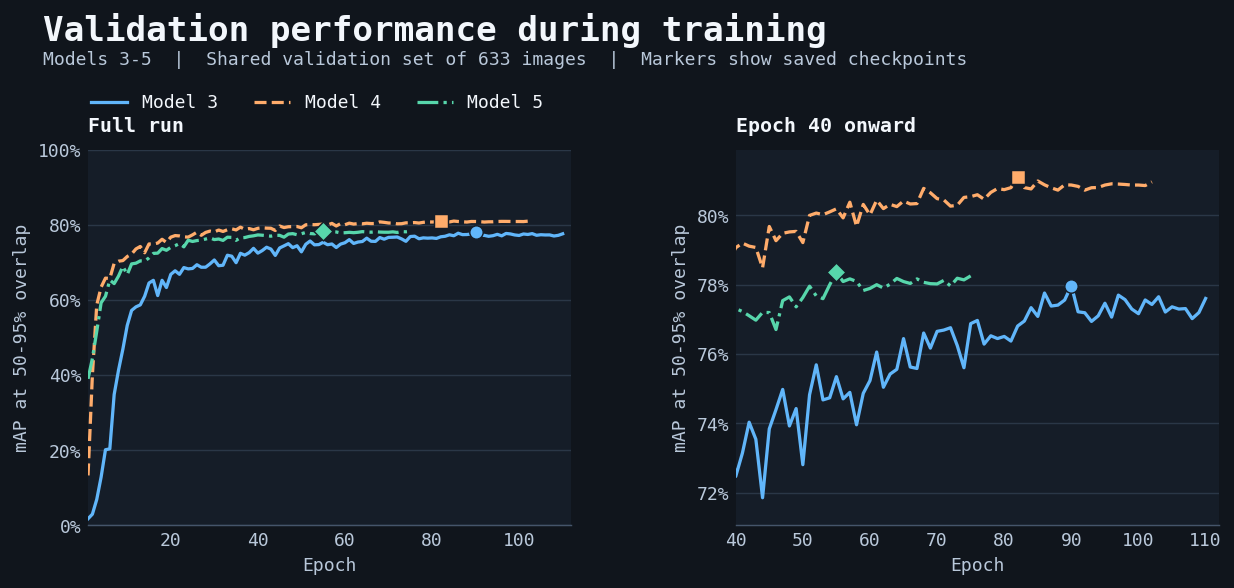

In [4]:
curves_figure, (full_axis, late_axis) = plt.subplots(1, 2, figsize=(10, 4.9))
curves_figure.subplots_adjust(
    left=0.09, right=0.96, top=0.74, bottom=0.15, wspace=0.34,
)
add_figure_heading(
    curves_figure,
    "Validation performance during training",
    "Models 3-5  |  Shared validation set of 633 images  |  Markers show saved checkpoints",
)

zoom_start = 40
validation_metric = "val_map50_95"
late_epochs = training[training["epoch"] >= zoom_start]
late_minimum = late_epochs[validation_metric].min()
late_maximum = late_epochs[validation_metric].max()
line_styles = {3: "-", 4: "--", 5: "-."}
checkpoint_markers = {3: "o", 4: "s", 5: "D"}

for model, epochs in training.groupby("model"):
    saved_epoch = epochs[epochs["is_best_epoch"]]
    for axis in (full_axis, late_axis):
        axis.plot(
            epochs["epoch"], epochs[validation_metric],
            color=model_colors[model], linestyle=line_styles[model],
            linewidth=1.8, label=model_labels[model],
        )
        axis.scatter(
            saved_epoch["epoch"], saved_epoch[validation_metric],
            color=model_colors[model], marker=checkpoint_markers[model],
            edgecolors=plot_background, linewidths=0.8, s=55, zorder=3,
        )

full_axis.set_title("Full run", loc="left")
full_axis.set_xlim(1, training["epoch"].max() + 2)
full_axis.set_ylim(0, 1)
late_axis.set_title(f"Epoch {zoom_start} onward", loc="left")
late_axis.set_xlim(zoom_start, training["epoch"].max() + 2)
late_axis.set_ylim(late_minimum - 0.008, late_maximum + 0.008)

for axis in (full_axis, late_axis):
    axis.set_xlabel("Epoch")
    axis.set_ylabel("mAP at 50-95% overlap")
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axis.grid(axis="y")

handles, labels = full_axis.get_legend_handles_labels()
curves_figure.legend(
    handles, labels, loc="upper left", bbox_to_anchor=(0.08, 0.853), ncol=3,
)

plt.show()

## Corner errors at live settings

Models 3 and 5 ran on the same 320 real photos at input size 1280 and a confidence
threshold of 0.60. The benchmark reports counts by corner angle. Rates by angle
would also require the total number of labeled corners in each angle group.

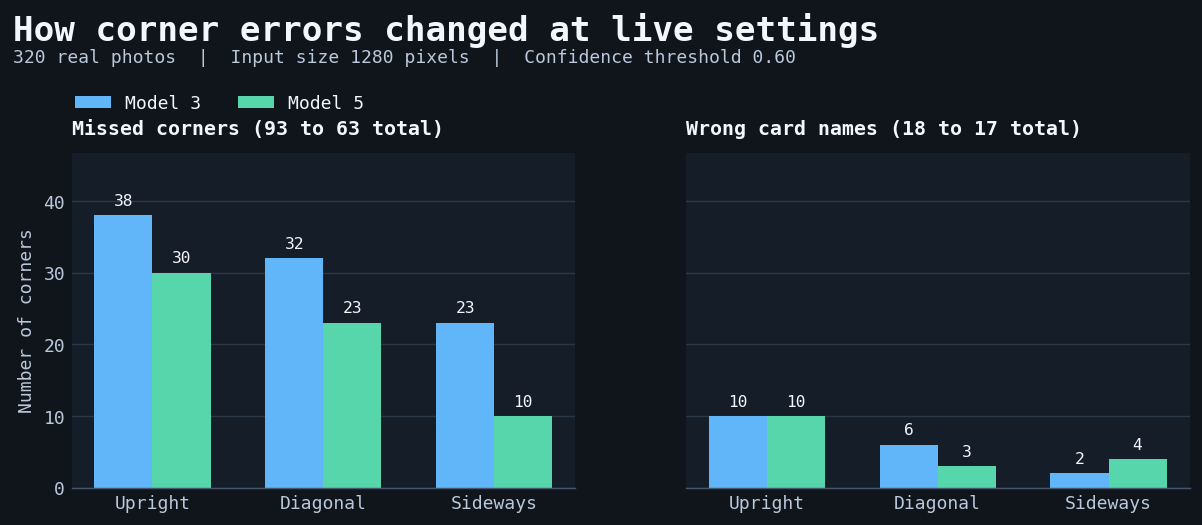

In [5]:
errors_figure, error_axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
errors_figure.subplots_adjust(
    left=0.10, right=0.96, top=0.72, bottom=0.16, wspace=0.22,
)
add_figure_heading(
    errors_figure,
    "How corner errors changed at live settings",
    "320 real photos  |  Input size 1280 pixels  |  Confidence threshold 0.60",
)

angle_order = ["upright", "diagonal", "sideways"]
error_panels = [("missed", "Missed corners"), ("wrong_name", "Wrong card names")]
comparison_models = sorted(errors["model"].unique())
angle_positions = list(range(len(angle_order)))
bar_width = 0.34
count_maximum = errors["corners"].max()

for axis, (error_type, label) in zip(error_axes, error_panels, strict=True):
    panel_errors = errors[errors["error_type"] == error_type]
    counts_by_angle = panel_errors.pivot(
        index="corner_angle", columns="model", values="corners",
    ).loc[angle_order, comparison_models]
    totals = [str(counts_by_angle[model].sum()) for model in comparison_models]
    axis.set_title(f"{label} ({' to '.join(totals)} total)", loc="left")

    for position, model in enumerate(comparison_models):
        offset = (position - (len(comparison_models) - 1) / 2) * bar_width
        bar_positions = [angle + offset for angle in angle_positions]
        bars = axis.bar(
            bar_positions, counts_by_angle[model], width=bar_width,
            color=model_colors[model], label=model_labels[model],
        )
        axis.bar_label(bars, padding=4, fontsize=9)

    axis.set_xticks(angle_positions, [angle.title() for angle in angle_order])
    axis.set_ylim(0, count_maximum * 1.23)
    axis.grid(axis="y")

error_axes[0].set_ylabel("Number of corners")
handles, labels = error_axes[0].get_legend_handles_labels()
errors_figure.legend(
    handles, labels, loc="upper left", bbox_to_anchor=(0.09, 0.845), ncol=2,
)

plt.show()

## Export figures

Set `export_figures` to `True` and run the cell to save vector PDFs and
300-dot-per-inch PNGs in `reportFigures/` alongside the source tables.
Exports replace files with the same names in that folder.

In [6]:
export_figures = False

if export_figures:
    figure_dir = data_dir / "reportFigures"
    figure_dir.mkdir(exist_ok=True)

    report_figures = {
        "heldOutAccuracy": accuracy_figure,
        "trainingImageCounts": dataset_figure,
        "validationCurves": curves_figure,
        "liveCornerErrors": errors_figure,
    }
    for filename, figure in report_figures.items():
        figure.savefig(figure_dir / f"{filename}.pdf")
        figure.savefig(figure_dir / f"{filename}.png", dpi=300)

    print(f"Saved {len(report_figures)} figures in two formats to {figure_dir}.")